# **Banff Working Group Code**

Goal: Use Celia's existing code (to take a (finite) rectangle module and extract its critical values) and make matching distance more precise by computing lines instead of sampling lines along a grid. 

## Import all the things.


In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan,ceil, floor
import csv # this is for reading input files

import sys 
sys.path.append('../Code/')
import modules as mod

# This reloads external modules every time a cell is run
# so we don't have to reboot kernel every time we modify classes.py
%load_ext autoreload
%autoreload 2

# Functions

In [2]:
# importer function to run over rectangle rect mod (.rmod) data file

def import_rmod(filename):
    # here we import a file with a list of rectangles and the modules they belong to. 
    data = []
    datalist = {}
    templist = {}
    rectangles = {}
    # ERROR CHECKING
    try: fd = open(filename, 'r')
    except OSError:
        print("Could not open/read file")
        sys.exit()
    with fd:
        reader = csv.reader(fd, delimiter=':')
        num_entries = 0
        for row in reader:
            if not row:
                print("error! row not found!")
            num_entries = num_entries + 1
            data.append(list(row))
            datalist = []
            rectangles = []
        # LINE BY LINE READ IN 
        i = 0
        for x in data:
            temprectx1y1 = [float(item) for item in data[i][0].split()]
            temprectx2y2 = [float(item) for item in data[i][1].split()]
            temprectx3y3 = [float(item) for item in data[i][2].split()]
            temprectx4y4 = [float(item) for item in data[i][3].split()]
            tempdim = [int(item) for item in data[i][4].split()]
            tempid = [int(item) for item in data[i][5].split()]
            templist = [temprectx1y1, temprectx2y2,temprectx3y3,temprectx4y4, tempdim, tempid]
            temprectangle = mod.Rectangle(temprectx1y1,temprectx2y2,temprectx3y3,temprectx4y4, tempdim, tempid)
            datalist.append(templist)
            rectangles.append(temprectangle)
            i += 1
            
        # all_rectangles is a list with x1y1, x2y2, dim, parent module
        # TODO: we shuffle the same data between variabes; this could be cleaned
        all_rectangles = datalist
        # for every line in all_rectangles, make a mod.Rectangle, 
        # and then rmod.addrect() to the module in the ith position in 
        # a module list, corresponding to the parent id.
        rects_list = []
        r_mods_list = [None] * len(all_rectangles)
        # this is the max possible size it could be, but prob smaller
        # TODO: double check that this does the right thing
        i = 0
        for x in all_rectangles:
            temp_rect = mod.Rectangle((x[0][0], x[0][1]), (x[1][0], x[1][1]),(x[2][0], x[2][1]),(x[3][0], x[3][1]), x[4][0], x[5][0])
            rects_list.append(temp_rect)
            i += 1
        j = 0
        for y in rects_list:
            if r_mods_list[y.find_parent()] == None:
                # we need to initialize
                r_mods_list[y.find_parent()] = mod.RectangleModule([y])
            else:
                # this mod already initialized. append. 
                r_mods_list[y.find_parent()].add_rectangle(y)
                # should be [y]?!
            j += 1
        # this is a sneaky way using list comprehension to remove Nones
        r_mods_list = [i for i in r_mods_list if i]
    return r_mods_list

def plot_r_mods(r_mods_list):
    # this sets, symmetrically, the y-intercept bounds for the red lines with slope = 1,1 
    # from which we sample the bottleneck approximations
    q = 4

    # for wbd: n is number of points in interval, t is length of interval
    n = 100 
    t = 5/n 

    # the r mod fig size, and bottleneck fig size, rspctvly
    figure_size = (8, 8)

    # these are the boundaries of the graphs which plot the r mods
    graph_left = -1
    graph_right = 10
    graph_bottom = -1
    graph_top = 10

    # these control the r mod figure
    edgecolor = 'blue'
    rectcolor = 'blue'
    linecolor = 'red'
    
    n_mods = len(r_mods_list)
    n_rects = 0
    for i in range(len(r_mods_list)):
        n_rects += r_mods_list[i].count_rectangles()
    print("we have ", n_rects, " rectangles")

    # this is the first of two sets of plots: it draws the rectangles representing the r mods
    fig, axes = plt.subplots(1, n_mods, figsize = figure_size)
    for i in range(n_mods):
        for j in range(r_mods_list[i].count_rectangles()):
            # this for loop runs over all rectangles in all mods. 
            # we need to hold it at this size to hit all rectangles     
            temp_rect = r_mods_list[i].rectangles[j]
            # this is the current rectangle

            origin = temp_rect.bottom_left 
            height = temp_rect.top_right[0]- origin[0]
            width = temp_rect.top_right[1]- origin[1]
            # note: infinity only goes to the right or up for now, not completely inf input
            tl = (temp_rect.top_left[0],min(temp_rect.top_left[1],graph_top))
            tr = (min(temp_rect.top_right[0],graph_right),min(temp_rect.top_right[1],graph_top))
            bl = temp_rect.bottom_left
            br = temp_rect.bottom_right
            br = (min(temp_rect.bottom_right[0],graph_right),temp_rect.bottom_right[1])
            modtype = 'finite '
            # if modtype should not be finite, this is decided in the two cases below, 
            # and plotted accordingly.
            # case one: right-infinite
            if graph_right < temp_rect.top_right[0]:
                t_linestyle = 'dashed'
                t_marker = " "
                b_linestyle = 'dashed'
                b_marker = " "
                width = 4
                modtype = 'inf '
            else: 
                t_linestyle = 'solid'
                t_marker = 'o'
                b_marker = 'o'
                b_linestyle = 'solid'
            # case two: top-infinite        
            if graph_top < temp_rect.top_left[1]:
                l_linestyle = 'dashed'
                l_marker = " " 
                r_linestyle = 'dashed'
                r_marker = " "
                height = 6
                modtype = 'inf '
            else:
                l_marker = 'o'
                l_linestyle = 'solid'
                r_marker = 'o'
                r_linestyle = 'solid'

            x = np.linspace(graph_left, graph_right, 1000)

            # this decides to plot a rectangle in the axis corresponding to its parent, 
            # in case the input list of rectangles isn't ordered according to module
            ax = axes[r_mods_list[i].rectangles[j].find_parent()]

            # lines to plot 
            ax.plot(x, x - q, linestyle='solid', color = linecolor) 
            ax.plot(x, x + q, linestyle='solid', color = linecolor) 

            # this is the rectangle
            # it plots by origin, height, and width, which are set 
            # to the boundary of the plot if the rectangle is infinite
            # (because patches doesn't know what to do with np.inf and doesn't plot anything)
            temp_patch = matplotlib.patches.Rectangle(origin, min(tr[0], graph_right) - origin[0], min(tr[1], graph_top) - origin[1], color = rectcolor, alpha = 0.1, fill = True)       
            ax.add_patch(temp_patch)

            # this plots the boundary of the rectangle
            ax.plot([tl[0], tr[0]], [tl[1], tr[1]], marker = t_marker, color = edgecolor, alpha = 0.5, linestyle = t_linestyle)
            ax.plot([tl[0], bl[0]], [tl[1], bl[1]], marker = l_marker, color = edgecolor, alpha = 0.5, linestyle = l_linestyle)
            ax.plot([bl[0], br[0]], [bl[1], br[1]], marker = b_marker, color = edgecolor, alpha = 0.5, linestyle = b_linestyle)
            ax.plot([tr[0], br[0]], [tr[1], br[1]], marker = r_marker, color = edgecolor, alpha = 0.5, linestyle = r_linestyle)

            # graph options
            ax.set_xlim([graph_left, graph_right])
            ax.set_ylim([graph_bottom, graph_top])
            ax.set_aspect(1)
            ax.set_xlabel(modtype + 'Mod ' + str(i)) 
            fig.tight_layout()
            
def plot_bnecks(r_mods_list):
    # this sets, symmetrically, the y-intercept bounds for the red lines with slope = 1,1 
    # from which we sample the bottleneck approximations
    q = 4

    # for wbd: n is number of points in interval, t is length of interval
    n = 100 
    t = 5/n 

    # the r mod fig size, and bottleneck fig size, rspctvly
    figure_b_size = (8, 5)
    
    # second plot: the pwise bottleneck of all input mods
    ii = 0
    jj = 0
    fig, ax = plt.subplots(figsize = figure_b_size)
    for M in r_mods_list: 
        for N in r_mods_list:
            if ii < jj:
                # this gets rid of half of the matrix of entries, 
                # keeping only the lower half. That way if we have
                # wlog (1,3), we don't also get (3,1). 
                # for sanity checks: add in equality with ii <= jj.
                # then bottleneck will be zero at equality.

                ## Family of lines in same equivalence class             
                Lines = []
                wbd = []
                x = []
                for b in np.linspace(-q, q, 100):
                    x.append(b)
                    line = mod.Line((1,1), (b , -b))
                    Lines.append(line)
                    d = mod.compute_weighted_bottleneck(M, N, line)
                    wbd.append(d)
                ax.set_aspect('auto')
                ax.plot(x, wbd, 'D', markersize = 15, alpha = 0.2, label='M' + str(jj) + ' vs M'+ str(ii))
                ax.set_xlabel('Value of b')
                ax.set_ylabel('weighted bottleneck distance')
                ax.legend()
            jj += 1
        ii += 1
        jj = 0    
    plt.show()

In [3]:
# r_mods_list = import_rmod('../data/sample.rmod')
r_mods_list = import_rmod('../data/sample_inf.rmod')
i = 0
for z in r_mods_list:
    print("Rectangle module", i , "info: ")
    print(z.rectangles)
    i += 1
# stopping point: right now, r_mods_list
# is a list of all of the modules from the rmod file. 
# next: incorporate this into function, and add printing
# to the rmods class in the modules file for error checking
# we can have duplicates of rectangles, but give a warning if so.
# types: right inf, top inf, completely inf, completely finite
# add error checking for types of inf, in case x and y mismatched or so




Rectangle module 0 info: 
[(dim is 1. Parent mod is 0. 
 Coords: 
 (2.0, 7.0) __________ (7.0, 7.0) 
           |          | 
           |__________| 
 (2.0, 0.0)            (7.0, 0.0) 
 ), (dim is 1. Parent mod is 0. 
 Coords: 
 (0.0, 3.0) __________ (5.0, 3.0) 
           |          | 
           |__________| 
 (0.0, 1.0)            (5.0, 1.0) 
 )]
Rectangle module 1 info: 
[(dim is 1. Parent mod is 1. 
 Coords: 
 (2.0, 7.0) __________ (7.0, 7.0) 
           |          | 
           |__________| 
 (2.0, 0.0)            (7.0, 0.0) 
 ), (dim is 1. Parent mod is 1. 
 Coords: 
 (0.0, 3.0) __________ (5.0, 3.0) 
           |          | 
           |__________| 
 (0.0, 1.0)            (5.0, 1.0) 
 )]


## Add lines and compute crit pts. 

In [4]:
L = mod.Line((1,1),(0,0))
L_low = mod.Line((1,1),(1/2,-1/2))
L_up = mod.line_through_2points((0,3),(7,10))
L_up.b

for i in range(0,len(r_mods_list)):
    M = r_mods_list[i]
#     M.print_mod_info()
    [inter_m1, param_m1] = M.find_intersection(L_low)
#     print("inter of Module ", i, " : ", inter_m1,"\n")
    dgmM = M.compute_barcode(L_low)
#     print("DGM of Module ", i, " : ",dgmM,"\n")
#     print("crit + LUB of Module ", i, " : ", M.find_critical_pts() + M.closure_lub(),"\n")

## Plotting all of the modules

we have  4  rectangles


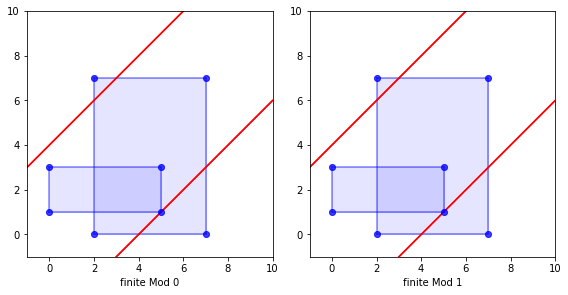

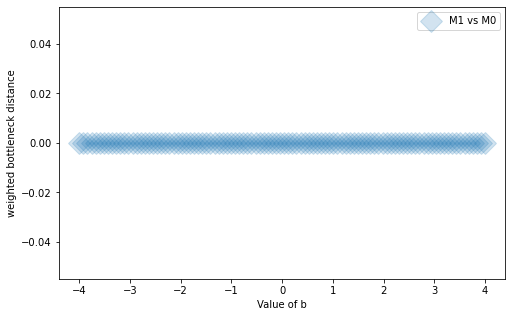

In [5]:
plot_r_mods(r_mods_list)
plot_bnecks(r_mods_list)

In [6]:
M = r_mods_list[0]
N = r_mods_list[1]
line = mod.Line((1,1), (1.75 , -1.75))
mod.compute_weighted_bottleneck(M,N,line)

1.946939626193803e-308

# TO DO 

### ERROR CHECKING, importer func + mod class: 
- mod.rectmod : check that all dimensions are the same in a mod
- remove duplicate rectangles if any, or at least warn
- check that numbers make sense, like dim is + 
- also check sensible numbers in mod.rect 
- Question: could two parent modules share same rectangle?
- Plotting works only with right or top infinite rectangles, not totally inf
-issues: 
- inf (causes many problems, among them discontinuity)
- same verts in rectangle (so not a proper rectangle) (causes discont)
- other problems with rectangle: like being at an angle instead of x,y aligned
- add error checking to disallow bad rectangle input
- add error checking to make sure that all rectangles per mod have same dim
- allow option for separate plots since sometimes things get stacked
- for inf rectangles: do multiple coords need to be inf? or just one? 
- interval modules can be non-axis aligned, but not rect mods
- if we only have one module, we get the error of ax not being subscriptable
- add smart finding of lines

- infs: 
- if a coord is (inf inf), there is no rectangle displayed
- add a function computing diagrams
# - ADD A WIDGET TO DRAW RECTS
- smarten plot bound extraction so we don't get fake infs

## NOTES (eventually for a README)

An example of a line of input to an .rmod file: 

`0.0 7.0 : inf inf : 0 1 : 7 1 : 1 : 0 `

This defines a rectangle: four verts, dimension, parent module.
inf is converted automatically by python to np.inf: the following returns True. 

`if x[1][0] == float('inf'):
       print(x[1][0] == np.inf)`
       
Further, all inputs are converted to float, so it is fine to enter either ints or floats. 

Warning: the file should not end with empty lines. This can be checked in a text editor such as Sublime. 

Note: plotting the bottleneck distance seems compatible with inf pts. 

Add plotting of crit vals

# Case 2:2 pseudocode
for two modules ```M``` and `N`, and the closure of their crit pts ```c_M``` and `c_N
critical_input = c_M + c_N
for i in range(critical_input):
    for j in range(critical_input):
        if i < j: # this keeps only half of the matrix (i,j), so we don't have duplicates. 
            keep pair (critical_input[i], critical_input[j]). `
        


In [7]:
bob = [[(0,0),[0]],[(1,1),[1]],[(2,2),[2]]]
for x in bob: 
    if (0,0) in x:
        print("velcro")

velcro


we have  4  rectangles
lub of module 0  is  [(0.0, 1.0), (7.0, 1.0), (7.0, 7.0), (2.0, 7.0), (2.0, 1.0), (7.0, 0.0), (2.0, 0.0), (0.0, 3.0), (5.0, 1.0), (5.0, 7.0), (7.0, 3.0), (2.0, 3.0), (5.0, 3.0)] 

inner for loop:  1
inner for loop:  2
inner for loop:  3
inner for loop:  4
inner for loop:  5
inner for loop:  6
inner for loop:  7
inner for loop:  8
inner for loop:  9
inner for loop:  10
inner for loop:  11
inner for loop:  12
inner for loop:  13
outer for loop:  1
lub of module 1  is  [(0.0, 1.0), (7.0, 1.0), (7.0, 7.0), (2.0, 7.0), (2.0, 1.0), (7.0, 0.0), (2.0, 0.0), (0.0, 3.0), (5.0, 1.0), (5.0, 7.0), (7.0, 3.0), (2.0, 3.0), (5.0, 3.0)] 

inner for loop:  1
inner for loop:  2
inner for loop:  3
inner for loop:  4
inner for loop:  5
inner for loop:  6
inner for loop:  7
inner for loop:  8
inner for loop:  9
inner for loop:  10
inner for loop:  11
inner for loop:  12
inner for loop:  13
outer for loop:  2
(0.0, 1.0) [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,

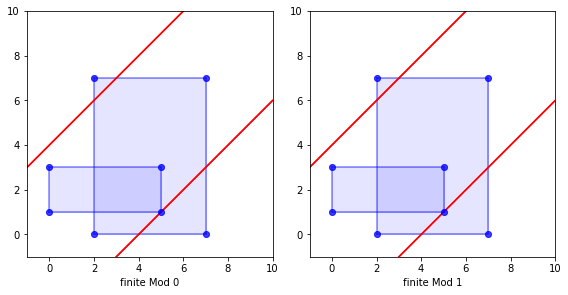

In [8]:
rr_mods_list = import_rmod('../data/sample_inf.rmod')
plot_r_mods(rr_mods_list)

# below we calculate critical values, and then add info to them by 
# adding them to the critical_val class
i = 0
all_closed_critical_vals = []
temp_crit_val_list = []
counter_1 = 0

for modulee in rr_mods_list:
    print("lub of module", i," is ",modulee.closure_lub(), "\n")
    temp_crit_val_list = modulee.closure_lub()
    # temp_c_v_l is a list of vals computed for one module
    counter_2 = 0
    for val in temp_crit_val_list:
        # if cv is already in set, add parent module to it
        # else, add cv to set
        temp_vall = mod.critical_val(val)
        temp_vall.add_parent(i)
        all_closed_critical_vals.append(temp_vall)
        counter_2 += 1
        print("inner for loop: ",counter_2)
    i +=1
    counter_1 += 1
    print("outer for loop: ",counter_1)

    
# maybe it's easier to merge duplicates here, instead of doing it as we go
# usage example
# print("thing is here: ",all_closed_critical_vals,"\n")
for c in all_closed_critical_vals:
    print(c.coords, c.parent_module)
        
# next lots of for loops
# remove duplication of critical values, but have critical value 
# remember list of parents rather than single 

M = ['a','b','c']
N = ['x','y','z']
Q = M + N
quadruples = set({})
for i in range(0, len(Q)):
    for j in range(i + 1, len(Q)):
        for k in range(j + 1, len(Q)):
            for l in range(k + 1, len(Q)):
                temp_quad = (Q[i],Q[j],Q[k],Q[l])
                # I think that the for loops already remove duplicates and permutations, 
                # but just in case we add temp_quad to a set, which don't allow duplicates.
                quadruples.add(temp_quad)
                
# print(quadruples)